In [1]:
#SHAP for Logistic Regression: which features does the model rely on? (RQ3)

In [2]:
import warnings
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

df = pd.read_csv("../data/oasis_longitudinal.csv")
df["label"] = (df["CDR"] > 0).astype(int)
df["Sex"] = (df["M/F"] == "M").astype(int)

y = df["label"]
groups = df["Subject ID"]

feature_sets = {
    "B (no MMSE)": ["Age", "Sex", "EDUC", "SES", "eTIV", "nWBV"],
    "A (with MMSE)": ["Age", "Sex", "EDUC", "SES", "eTIV", "nWBV", "MMSE"],
}

C:\Users\PMLS\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def shap_logreg(feats, seed=0):
    X = df[feats]
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    sv_all = np.zeros((len(df), len(feats)))   # SHAP values for every visit
    x_all = np.zeros((len(df), len(feats)))    # feature values, for the plot colours

    for train_idx, test_idx in cv.split(X, y, groups):
        # fill missing values and scale, learned from the training people only
        imputer = SimpleImputer(strategy="median").fit(X.iloc[train_idx])
        X_train_imp = imputer.transform(X.iloc[train_idx])
        X_test_imp = imputer.transform(X.iloc[test_idx])
        scaler = StandardScaler().fit(X_train_imp)
        X_train_t = scaler.transform(X_train_imp)
        X_test_t = scaler.transform(X_test_imp)

        lr = LogisticRegression(max_iter=1000).fit(X_train_t, y.iloc[train_idx])

        # explain only the people the model did NOT train on
        explainer = shap.LinearExplainer(lr, X_train_t)
        sv_all[test_idx] = explainer.shap_values(X_test_t)
        x_all[test_idx] = X_test_imp

    return sv_all, pd.DataFrame(x_all, columns=feats)

Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


B (no MMSE)
nWBV    0.833
Sex     0.713
EDUC    0.621
Age     0.469
eTIV    0.382
SES     0.235
dtype: float64



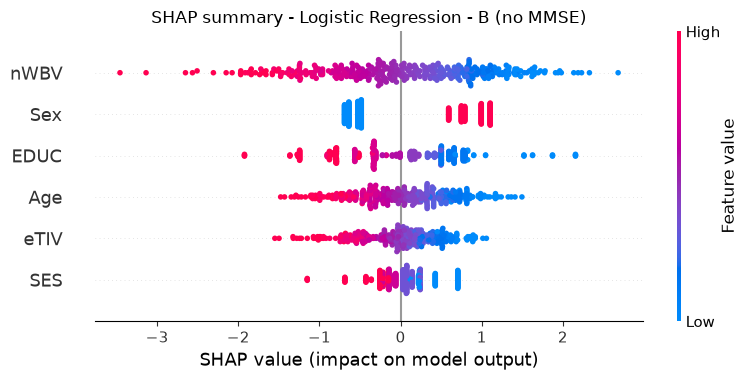

Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


A (with MMSE)
MMSE    2.105
Sex     0.764
nWBV    0.695
EDUC    0.606
Age     0.544
SES     0.419
eTIV    0.392
dtype: float64



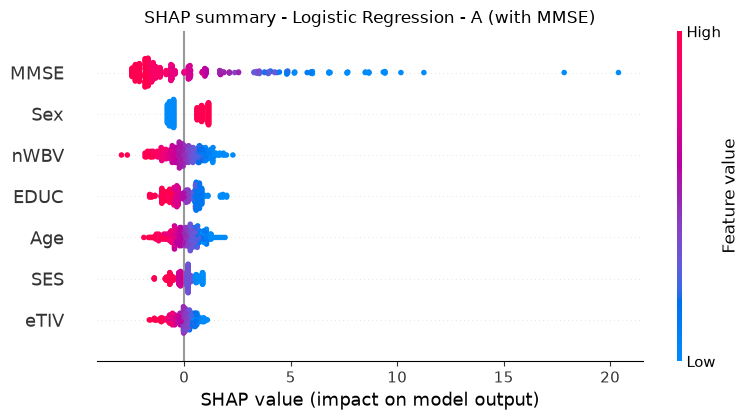

In [4]:
for exp_name, feats in feature_sets.items():
    sv, X_show = shap_logreg(feats)

    print(exp_name)
    importance = pd.Series(np.abs(sv).mean(axis=0), index=feats).sort_values(ascending=False)
    print(importance.round(3))
    print()

    shap.summary_plot(sv, X_show, show=False)
    plt.title(f"SHAP summary - Logistic Regression - {exp_name}")
    plt.tight_layout()
    plt.savefig(f"../figures/shap_logreg_{exp_name[0]}.png", dpi=150)
    plt.show()

In [5]:
print(df[["Age", "nWBV", "eTIV", "EDUC", "SES"]].corr().round(2))
print()
print("Visits with dementia signs, by sex (1 = male):")
print(df.groupby("Sex")["label"].agg(["mean", "size"]).round(2))
print()
df["age_group"] = pd.cut(df["Age"], bins=[59, 70, 80, 90, 100])
print("Visits with dementia signs, by age group:")
print(df.groupby("age_group", observed=True)["label"].agg(["mean", "size"]).round(2))

       Age  nWBV  eTIV  EDUC   SES
Age   1.00 -0.52  0.04 -0.03 -0.05
nWBV -0.52  1.00 -0.21 -0.01  0.09
eTIV  0.04 -0.21  1.00  0.26 -0.26
EDUC -0.03 -0.01  0.26  1.00 -0.72
SES  -0.05  0.09 -0.26 -0.72  1.00

Visits with dementia signs, by sex (1 = male):
     mean  size
Sex            
0    0.33   213
1    0.60   160

Visits with dementia signs, by age group:
           mean  size
age_group            
(59, 70]   0.42    77
(70, 80]   0.47   173
(80, 90]   0.45   107
(90, 100]  0.31    16
